In [64]:
%pip install -q -U kagglehub

In [65]:
import os
import glob
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, LSTM, Dense, Dropout, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings("ignore")
np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [66]:
DATA_DIR = "/content/har_data"
os.makedirs(DATA_DIR, exist_ok=True)

try:
    import kagglehub

    dataset_path = kagglehub.dataset_download(
        "uciml/human-activity-recognition-with-smartphones"
    )

    print("Kaggle dataset downloaded!")
    print("Dataset path:", dataset_path)

except Exception as e:
    print("Kaggle download failed:", str(e)[:300])
    print("Trying original UCI dataset as fallback...")

    zip_path = "/content/uci_har.zip"
    url = (
        "https://archive.ics.uci.edu/static/public/240/"
        "human+activity+recognition+using+smartphones.zip"
    )

    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

    print("UCI dataset downloaded successfully!")

100%|██████████| 24.5M/24.5M [00:01<00:00, 16.8MB/s]

Extracting files...


Kaggle dataset downloaded!
Dataset path: /root/.cache/kagglehub/datasets/uciml/human-activity-recognition-with-smartphones/versions/2


In [67]:
search_root = (
    dataset_path
    if "dataset_path" in globals()
    else DATA_DIR
)

csv_files = glob.glob(
    os.path.join(search_root, "**", "*.csv"),
    recursive=True
)

print("CSV files found:", len(csv_files))

for f in csv_files[:20]:
    print(f)

CSV files found: 2
/root/.cache/kagglehub/datasets/uciml/human-activity-recognition-with-smartphones/versions/2/test.csv
/root/.cache/kagglehub/datasets/uciml/human-activity-recognition-with-smartphones/versions/2/train.csv


In [68]:
train_file = next(
    (f for f in csv_files
     if os.path.basename(f).lower() == "train.csv"),
    None
)

test_file = next(
    (f for f in csv_files
     if os.path.basename(f).lower() == "test.csv"),
    None
)

if train_file is not None:
    train_df = pd.read_csv(train_file)
    print("Training CSV:", train_file)
    print("Training shape:", train_df.shape)

else:
    # Fallback to the original UCI text files
    uci_root = os.path.join(DATA_DIR, "UCI HAR Dataset")

    if not os.path.exists(uci_root):
        matches = glob.glob(
            os.path.join(DATA_DIR, "**", "X_train.txt"),
            recursive=True
        )
        if matches:
            uci_root = os.path.dirname(
                os.path.dirname(matches[0])
            )

    X_train_path = os.path.join(uci_root, "train", "X_train.txt")
    y_train_path = os.path.join(uci_root, "train", "y_train.txt")
    X_test_path = os.path.join(uci_root, "test", "X_test.txt")
    y_test_path = os.path.join(uci_root, "test", "y_test.txt")

    if not os.path.exists(X_train_path):
        raise FileNotFoundError(
            "Training data not found. Check Cell 3 output."
        )

    X_original_train = pd.read_csv(
        X_train_path, sep=r"\s+", header=None
    )
    X_original_test = pd.read_csv(
        X_test_path, sep=r"\s+", header=None
    )

    y_original_train = pd.read_csv(
        y_train_path, sep=r"\s+", header=None
    ).iloc[:, 0]

    y_original_test = pd.read_csv(
        y_test_path, sep=r"\s+", header=None
    ).iloc[:, 0]

    train_df = X_original_train.copy()
    train_df["Activity"] = y_original_train

    test_df = X_original_test.copy()
    test_df["Activity"] = y_original_test

    print("Original UCI train/test files loaded.")

print("Train shape:", train_df.shape)

if test_file is not None:
    test_df = pd.read_csv(test_file)
    print("Test shape:", test_df.shape)

Training CSV: /root/.cache/kagglehub/datasets/uciml/human-activity-recognition-with-smartphones/versions/2/train.csv
Training shape: (7352, 563)
Train shape: (7352, 563)
Test shape: (2947, 563)


In [70]:

from IPython.display import display as show_table

def find_target_column(df):
    possible = [
        "Activity", "activity", "activity_name",
        "ActivityName", "label", "Label", "target"
    ]

    for col in possible:
        if col in df.columns:
            return col

    return df.columns[-1]


target_col = find_target_column(train_df)

print("Target column:", target_col)
print("\nDataset preview:")

show_table(train_df.head())

print("\nMissing values:", train_df.isnull().sum().sum())

print("\nClass distribution:")
print(train_df[target_col].value_counts())


Target column: Activity

Dataset preview:


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING



Missing values: 0

Class distribution:
Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64


In [71]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

train_df = train_df.dropna(subset=[target_col]).copy()
train_df = train_df.drop_duplicates().reset_index(drop=True)

drop_cols = [target_col]

for col in train_df.columns:
    if str(col).strip().lower() in ["subject", "subject_id", "subjectid"]:
        drop_cols.append(col)

X_df = train_df.drop(columns=drop_cols)
X_df = X_df.select_dtypes(include=[np.number])
X_df = X_df.replace([np.inf, -np.inf], np.nan)
X_df = X_df.fillna(X_df.median()).fillna(0)

y_raw = train_df[target_col].astype(str)

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_raw)

class_names = encoder.classes_
num_classes = len(class_names)

print("Features:", X_df.shape)
print("Classes:", list(class_names))
print("Number of classes:", num_classes)

assert X_df.shape[1] > 0, "No numeric features found."
assert num_classes >= 2, "At least two classes are required."


Features: (7352, 561)
Classes: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
Number of classes: 6


In [72]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_val, y_train, y_val = train_test_split(
    X_df.to_numpy(dtype=np.float32),
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Training features:", X_train.shape[1])


Training samples: 5881
Validation samples: 1471
Training features: 561


In [73]:

import tensorflow as tf

tf.random.set_seed(42)

X_train_seq = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_val_seq = X_val.reshape(
    X_val.shape[0], X_val.shape[1], 1
)

y_train_cat = tf.keras.utils.to_categorical(
    y_train, num_classes=num_classes
)

y_val_cat = tf.keras.utils.to_categorical(
    y_val, num_classes=num_classes
)

print("Training sequence:", X_train_seq.shape)
print("Validation sequence:", X_val_seq.shape)
print("Labels:", y_train_cat.shape)


Training sequence: (5881, 561, 1)
Validation sequence: (1471, 561, 1)
Labels: (5881, 6)


In [74]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, LSTM, Dense, Dropout, BatchNormalization
)

model = Sequential([
    Input(shape=(X_train_seq.shape[1], 1)),
    LSTM(64, return_sequences=True),
    BatchNormalization(),
    Dropout(0.30),
    LSTM(32),
    Dropout(0.30),
    Dense(64, activation="relu"),
    Dropout(0.20),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 561, 64)        │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 561, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 561, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,070 (125.27 KB)

 Trainable params: 31,942 (124.77 KB)

 Non-trainable params: 128 (512.00 B)

In [75]:

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train_seq,
    y_train_cat,
    validation_data=(X_val_seq, y_val_cat),
    epochs=30,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

print("LSTM training completed!")


Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 46ms/step - accuracy: 0.5258 - loss: 1.0896 - val_accuracy: 0.3698 - val_loss: 1.2386 - learning_rate: 0.0010
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.6739 - loss: 0.7182 - val_accuracy: 0.4351 - val_loss: 1.5082 - learning_rate: 0.0010
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.7126 - loss: 0.6394 - val_accuracy: 0.4500 - val_loss: 1.6588 - learning_rate: 0.0010
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.7290 - loss: 0.6193 - val_accuracy: 0.4731 - val_loss: 1.2140 - learning_rate: 0.0010
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.7837 - loss: 0.5349 - val_accuracy: 0.5738 - val_loss: 1.1286 - learning_rate: 0.0010
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.7941 - loss: 0.5191 - val_accuracy: 0.7729 - val_loss: 0.5151 - learning_rate: 0.0010
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.8067 - loss: 0.4874 - val_ac

In [76]:

val_loss, val_accuracy = model.evaluate(
    X_val_seq, y_val_cat, verbose=0
)

print("=" * 40)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")
print("=" * 40)


Validation Accuracy: 88.92%
Validation Loss: 0.2679


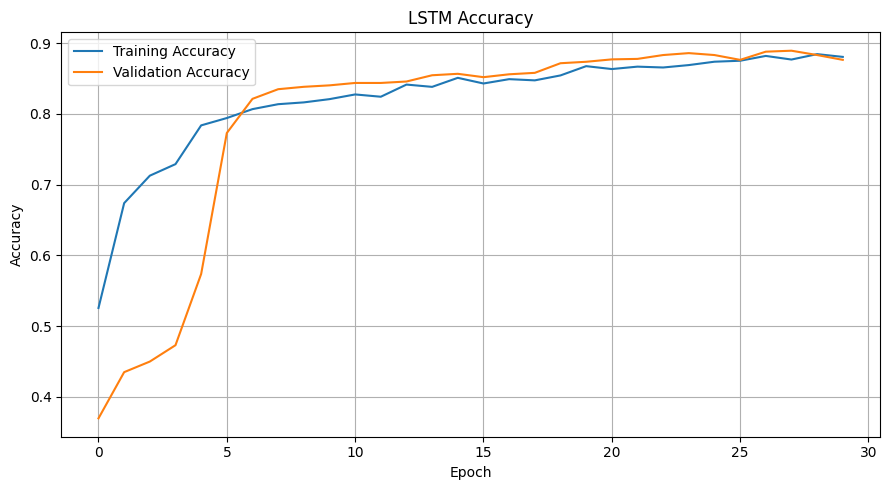

In [77]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


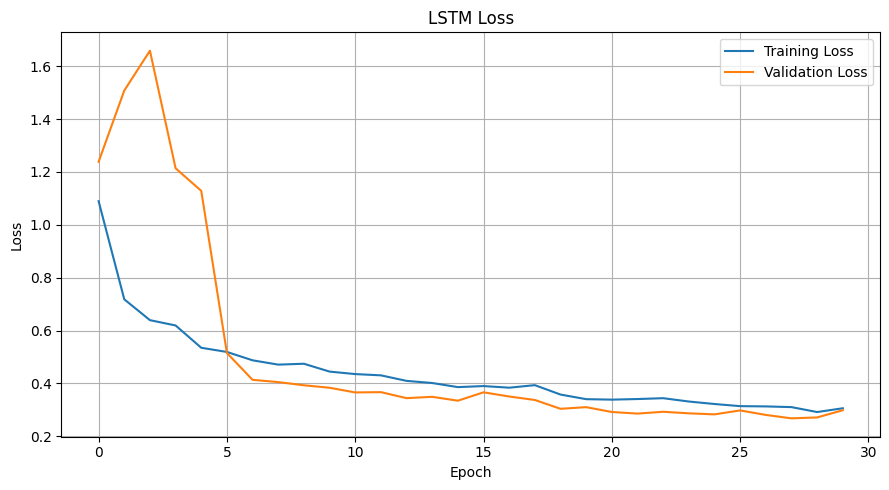

In [78]:

plt.figure(figsize=(9, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [79]:

from sklearn.metrics import accuracy_score

probabilities = model.predict(X_val_seq, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
y_true = y_val

print("Predictions generated!")
print("Accuracy:", f"{accuracy_score(y_true, y_pred) * 100:.2f}%")


Predictions generated!
Accuracy: 88.92%


In [80]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=[str(x) for x in class_names],
    zero_division=0
))


                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       282
           SITTING       0.89      0.84      0.86       257
          STANDING       0.86      0.90      0.88       275
           WALKING       0.88      0.87      0.88       245
WALKING_DOWNSTAIRS       0.92      0.82      0.87       197
  WALKING_UPSTAIRS       0.79      0.87      0.83       215

          accuracy                           0.89      1471
         macro avg       0.89      0.88      0.88      1471
      weighted avg       0.89      0.89      0.89      1471



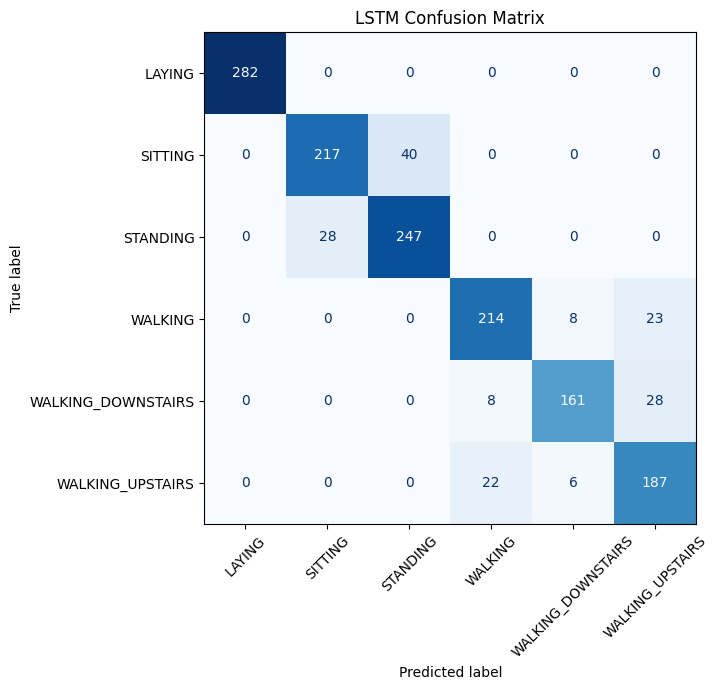

In [81]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
cm_display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)
plt.title("LSTM Confusion Matrix")
plt.tight_layout()
plt.show()


In [82]:

comparison = pd.DataFrame({
    "Actual Activity": encoder.inverse_transform(y_true),
    "Predicted Activity": encoder.inverse_transform(y_pred),
    "Correct": y_true == y_pred,
    "Confidence (%)": np.max(probabilities, axis=1) * 100
})

show_table(comparison.head(20))

print("Correct predictions:", int(comparison["Correct"].sum()))
print("Incorrect predictions:", int((~comparison["Correct"]).sum()))


,Actual Activity,Predicted Activity,Correct,Confidence (%)
0,WALKING_UPSTAIRS,WALKING_UPSTAIRS,True,98.068321
1,SITTING,SITTING,True,99.516823
2,SITTING,SITTING,True,62.446045
3,LAYING,LAYING,True,99.986519
4,WALKING,WALKING,True,97.602722
5,SITTING,SITTING,True,99.907936
6,WALKING_UPSTAIRS,WALKING_UPSTAIRS,True,74.310318
7,WALKING_UPSTAIRS,WALKING_UPSTAIRS,True,96.273109
8,LAYING,LAYING,True,99.998283
9,STANDING,STANDING,True,98.166100


Correct predictions: 1308
Incorrect predictions: 163


In [83]:

sample_index = 0

sample = X_val_seq[sample_index:sample_index + 1]
sample_probabilities = model.predict(sample, verbose=0)[0]

predicted_index = int(np.argmax(sample_probabilities))
actual_activity = encoder.inverse_transform(
    [y_val[sample_index]]
)[0]

print("Actual activity:", actual_activity)
print("Predicted activity:", class_names[predicted_index])
print(
    f"Confidence: {sample_probabilities[predicted_index] * 100:.2f}%"
)


Actual activity: WALKING_UPSTAIRS
Predicted activity: WALKING_UPSTAIRS
Confidence: 98.07%


In [84]:

import joblib

model.save("/content/har_lstm_model.keras")
joblib.dump(scaler, "/content/har_scaler.pkl")
joblib.dump(encoder, "/content/har_label_encoder.pkl")

print("Model saved successfully!")
print("Scaler saved successfully!")
print("Label encoder saved successfully!")


Model saved successfully!
Scaler saved successfully!
Label encoder saved successfully!


In [85]:

comparison.to_csv(
    "/content/har_lstm_predictions.csv",
    index=False
)

print("CSV exported successfully!")


CSV exported successfully!


In [86]:

from google.colab import files

files.download("/content/har_lstm_model.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [87]:

files.download("/content/har_lstm_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:

print("=" * 55)
print("HUMAN ACTIVITY RECOGNITION - LSTM PROJECT COMPLETED")
print("=" * 55)

print("Number of classes:", num_classes)
print("Training samples:", len(X_train_seq))
print("Validation samples:", len(X_val_seq))
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation loss: {val_loss:.4f}")
print("Accuracy and loss graphs generated.")
print("Classification report generated.")
print("Confusion matrix generated.")
print("Predictions CSV saved.")
print("HUMAN ACTIVITY RECOGNITION PROJECT COMPLETED")
print("=" * 55)


HUMAN ACTIVITY RECOGNITION - LSTM PROJECT COMPLETED
Number of classes: 6
Training samples: 5881
Validation samples: 1471
Validation accuracy: 88.92%
Validation loss: 0.2679
Accuracy and loss graphs generated.
Classification report generated.
Confusion matrix generated.
Predictions CSV saved.
HUMAN ACTIVITY RECOGNITION PROJECT COMPLETED
